In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

First five rows:


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium



Dataset shape: (2823, 25)

Columns:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE', 'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


In [4]:
#Data pre processing:
df = df.drop_duplicates()

features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

X = df[features].copy()

# Convert columns to numeric values
X = X.apply(pd.to_numeric, errors="coerce")

# Handle missing and infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

print("Selected features:")
display(X.head())

print("Data shape after preprocessing:", X.shape)

Selected features:


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
0,30,95.70,2871.00,95
1,34,81.35,2765.90,95
2,41,94.74,3884.34,95
3,45,83.26,3746.70,95
4,49,100.00,5205.27,95


Data shape after preprocessing: (2823, 4)


In [5]:
#Feature Scaling:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling completed.")

Feature scaling completed.


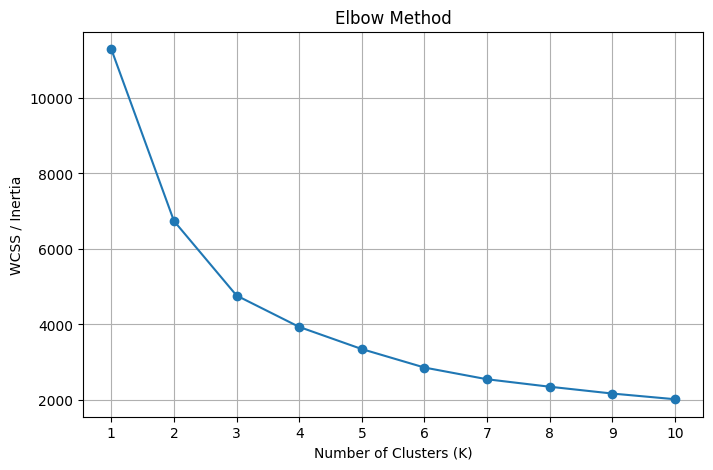

In [7]:
#Elbow method:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [10]:
#Apply K-Means Clustering
optimal_k = 3

kmeans = KMeans(
        n_clusters=optimal_k,
        random_state=42,
        n_init=10
)
clusters = kmeans.fit_predict(X_scaled)

X_result = X.copy()
X_result["Cluster"] = clusters

print("Cluster assignment:")
display(X_result.head(10))

Cluster assignment:


,QUANTITYORDERED,PRICEEACH,SALES,MSRP,Cluster
0,30,95.70,2871.00,95,2
1,34,81.35,2765.90,95,2
2,41,94.74,3884.34,95,1
3,45,83.26,3746.70,95,1
4,49,100.00,5205.27,95,1
5,36,96.66,3479.76,95,2
6,29,86.13,2497.77,95,2
7,48,100.00,5512.32,95,1
8,22,98.57,2168.54,95,2
9,41,100.00,4708.44,95,1


Number of records in each cluster:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64


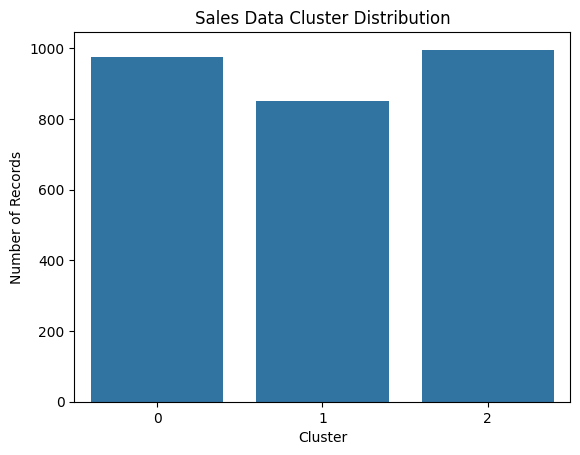

In [11]:
#Cluster Distribution
print("Number of records in each cluster:")
print(X_result["Cluster"].value_counts().sort_index())
sns.countplot(data=X_result, x="Cluster")
plt.title("Sales Data Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.show()

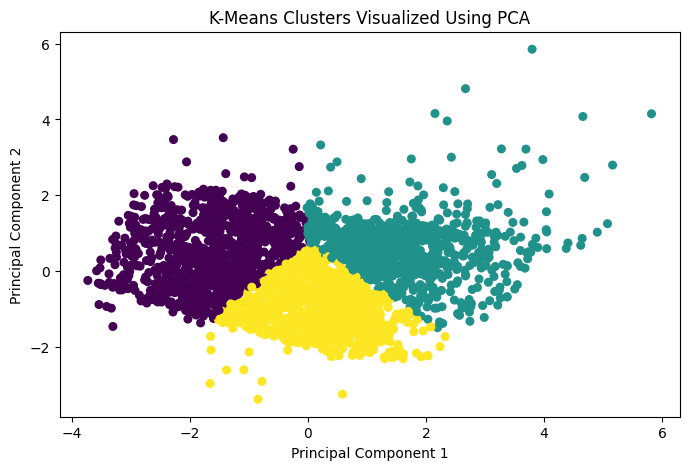

In [12]:
#Cluster Visualization Using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=30
)
plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

In [13]:
#Cluster Analysis
cluster_summary = X_result.groupby("Cluster")[features].mean()
display(cluster_summary.round(2))

,QUANTITYORDERED,PRICEEACH,SALES,MSRP
Cluster,,,,
0,35.21,59.55,2101.08,64.15
1,43.72,97.48,5720.08,127.89
2,27.60,95.44,3123.06,113.27
